**Lab 03** | **Name: Tayyab Hanif** | **Roll No: 2024-SE-11**

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)
print("OpenCV Version:", cv2.__version__)

print("All Libraries Imported Successfully!")

NumPy Version: 2.4.6
OpenCV Version: 5.0.0
All Libraries Imported Successfully!


In [2]:
import os

print("Current Folder:", os.getcwd())
print("Files:", os.listdir())

Current Folder: C:\Users\Admin\Desktop\dip-lab-03
Files: ['.ipynb_checkpoints', '2024-SE-11-Lab03.ipynb', 'Leisure.jpg']


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Leisure.jpg", cv2.IMREAD_GRAYSCALE)

if img is not None:
    print("Image loaded successfully!")
    print("Shape:", img.shape)
    print("Data Type:", img.dtype)
    print("Minimum Pixel:", img.min())
    print("Maximum Pixel:", img.max())
else:
    print("Image not found!")

Image loaded successfully!
Shape: (1536, 1024)
Data Type: uint8
Minimum Pixel: 0
Maximum Pixel: 254


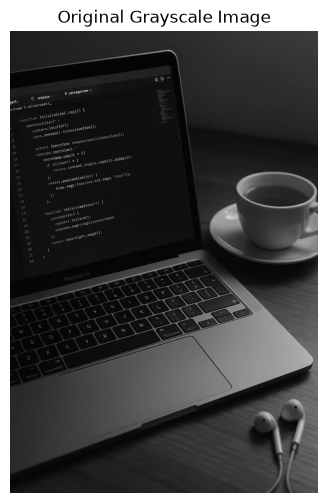

In [4]:
plt.figure(figsize=(6, 6))

plt.imshow(img, cmap="gray", vmin=0, vmax=255)

plt.title("Original Grayscale Image")
plt.axis("off")

plt.show()

In [5]:
pixels = np.array([30, 80, 128, 180, 240])

# Convert into int16
pixels = pixels.astype(np.int16)

# Brightness +40
bright_raw = pixels + 40
bright = np.clip(bright_raw, 0, 255).astype(np.uint8)

# Brightness -40
dark_raw = pixels - 40
dark = np.clip(dark_raw, 0, 255).astype(np.uint8)

print("Original Pixels:", pixels)
print("Bright Raw:", bright_raw)
print("Bright Final:", bright)

print("Dark Raw:", dark_raw)
print("Dark Final:", dark)

Original Pixels: [ 30  80 128 180 240]
Bright Raw: [ 70 120 168 220 280]
Bright Final: [ 70 120 168 220 255]
Dark Raw: [-10  40  88 140 200]
Dark Final: [  0  40  88 140 200]


In [6]:
# Convert image into int16
img_int = img.astype(np.int16)

# Increase brightness by 40
bright_img = np.clip(
    img_int + 40, 0, 255
).astype(np.uint8)

# Decrease brightness by 40
dark_img = np.clip(
    img_int - 40, 0, 255
).astype(np.uint8)

print("Brightness adjustment completed!")

Brightness adjustment completed!


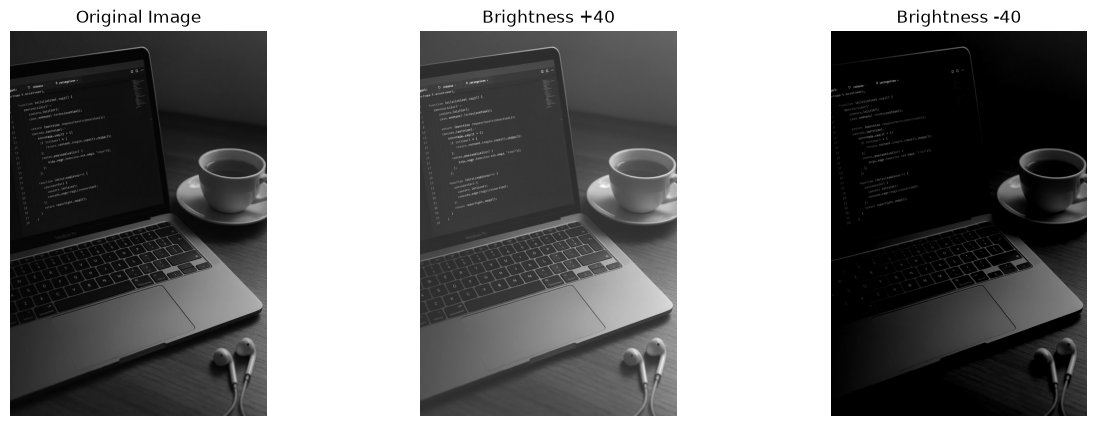

In [7]:
plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

# Bright image
plt.subplot(1, 3, 2)
plt.imshow(bright_img, cmap="gray", vmin=0, vmax=255)
plt.title("Brightness +40")
plt.axis("off")

# Dark image
plt.subplot(1, 3, 3)
plt.imshow(dark_img, cmap="gray", vmin=0, vmax=255)
plt.title("Brightness -40")
plt.axis("off")

plt.show()

In [8]:
bright_loop = np.zeros(img.shape, dtype=np.uint8)

rows, cols = img.shape

for i in range(rows):
    for j in range(cols):

        value = int(img[i, j]) + 40

        if value > 255:
            value = 255

        bright_loop[i, j] = value

print("Both results are same:",
      np.array_equal(bright_img, bright_loop))

Both results are same: True


In [9]:
#Task 2 — Linear Contrast from Zero
# Original pixels
pixels = np.array([30, 80, 128, 180, 240])

# Convert into int16
pixels = pixels.astype(np.int16)

# Linear contrast
alpha = 1.5
beta = 0

# Apply formula
raw = alpha * pixels + beta

# Clip and convert to uint8
contrast = np.clip(raw, 0, 255).astype(np.uint8)

print("Original Pixels:", pixels)
print("Raw Values:", raw)
print("Final Values:", contrast)

Original Pixels: [ 30  80 128 180 240]
Raw Values: [ 45. 120. 192. 270. 360.]
Final Values: [ 45 120 192 255 255]


In [10]:
# Set alpha and beta
alpha = 1.5
beta = 0

# Convert image into float32
img_float = img.astype(np.float32)

# Apply linear contrast formula
contrast_img = alpha * img_float + beta

# Clip values between 0 and 255
contrast_img = np.clip(
    contrast_img, 0, 255
).astype(np.uint8)

print("Linear contrast applied successfully!")

Linear contrast applied successfully!


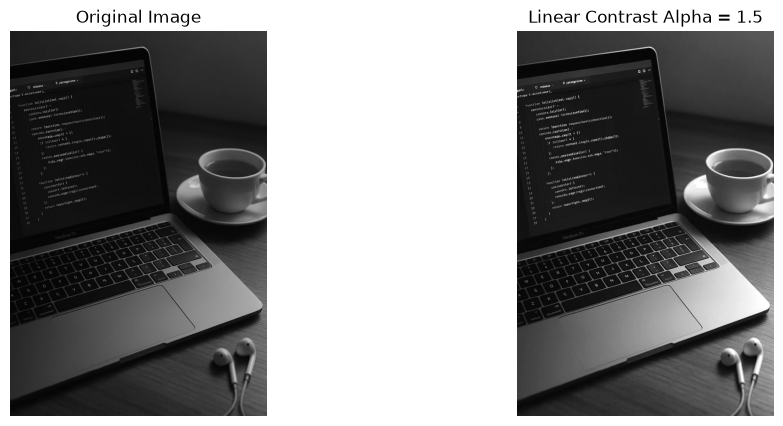

In [11]:
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

# Contrast image
plt.subplot(1, 2, 2)
plt.imshow(contrast_img, cmap="gray", vmin=0, vmax=255)
plt.title("Linear Contrast Alpha = 1.5")
plt.axis("off")

plt.show()

In [12]:
# Task 3 — Contrast Centered at 128
# Original pixels
pixels = np.array([30, 80, 128, 180, 240])

# Convert to int16
pixels = pixels.astype(np.int16)

# Alpha values
alpha1 = 1.5
alpha2 = 0.5

# Contrast centered at 128
raw1 = (pixels - 128) * alpha1 + 128
raw2 = (pixels - 128) * alpha2 + 128

# Clip values and convert to uint8
result1 = np.clip(raw1, 0, 255).astype(np.uint8)
result2 = np.clip(raw2, 0, 255).astype(np.uint8)

print("Original Pixels:", pixels)

print("\nAlpha = 1.5")
print("Raw Values:", raw1)
print("Final Values:", result1)

print("\nAlpha = 0.5")
print("Raw Values:", raw2)
print("Final Values:", result2)

Original Pixels: [ 30  80 128 180 240]

Alpha = 1.5
Raw Values: [-19.  56. 128. 206. 296.]
Final Values: [  0  56 128 206 255]

Alpha = 0.5
Raw Values: [ 79. 104. 128. 154. 184.]
Final Values: [ 79 104 128 154 184]


In [13]:
# Convert original image to float32
img_float = img.astype(np.float32)

# Alpha = 1.5
contrast_15 = (img_float - 128) * 1.5 + 128

contrast_15 = np.clip(
    contrast_15, 0, 255
).astype(np.uint8)

# Alpha = 0.5
contrast_05 = (img_float - 128) * 0.5 + 128

contrast_05 = np.clip(
    contrast_05, 0, 255
).astype(np.uint8)

print("Both contrast transformations completed!")

Both contrast transformations completed!


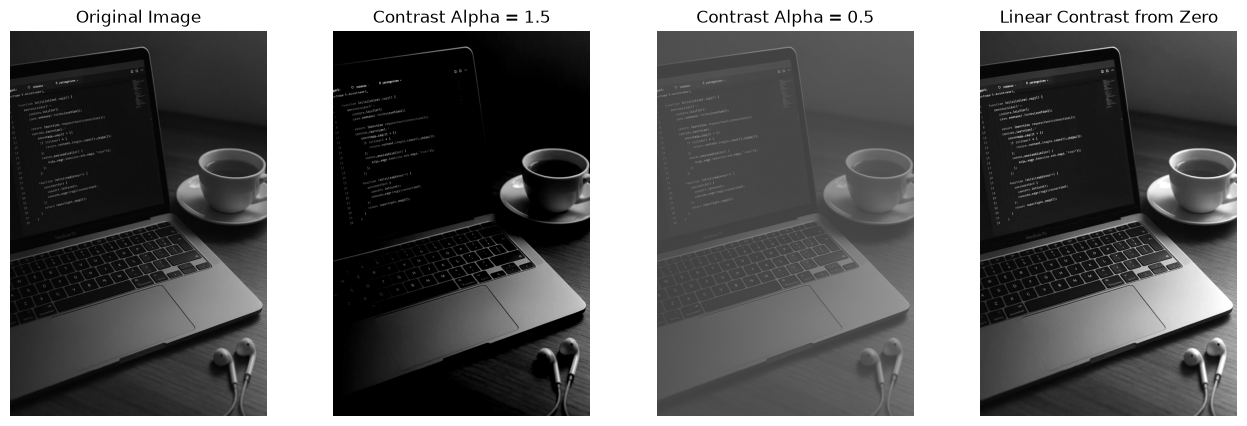

In [14]:
plt.figure(figsize=(16, 5))

# Original
plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

# Alpha 1.5
plt.subplot(1, 4, 2)
plt.imshow(contrast_15, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast Alpha = 1.5")
plt.axis("off")

# Alpha 0.5
plt.subplot(1, 4, 3)
plt.imshow(contrast_05, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast Alpha = 0.5")
plt.axis("off")

# Task 2 comparison
plt.subplot(1, 4, 4)
plt.imshow(contrast_img, cmap="gray", vmin=0, vmax=255)
plt.title("Linear Contrast from Zero")
plt.axis("off")

plt.show()

In [15]:
# Task 4 — Image Negative
# Original pixels
pixels = np.array([30, 80, 128, 180, 240])

# Image negative formula
negative = 255 - pixels

print("Original Pixels:", pixels)
print("Negative Pixels:", negative)

Original Pixels: [ 30  80 128 180 240]
Negative Pixels: [225 175 127  75  15]


In [16]:
# Apply negative again
negative_again = 255 - negative

print("Original:", pixels)
print("Negative Again:", negative_again)

# Compare both arrays
print("Both are same:", np.array_equal(pixels, negative_again))

Original: [ 30  80 128 180 240]
Negative Again: [ 30  80 128 180 240]
Both are same: True


In [17]:
# Create negative image
negative_img = 255 - img

print("Image Negative Created Successfully!")

Image Negative Created Successfully!


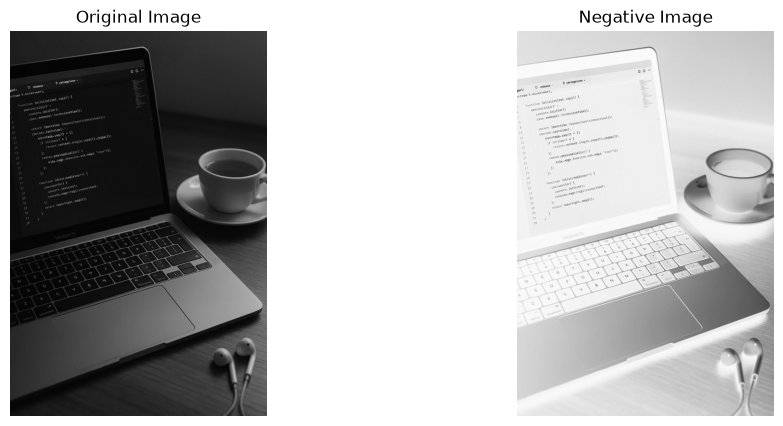

In [18]:
plt.figure(figsize=(12, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

# Negative Image
plt.subplot(1, 2, 2)
plt.imshow(negative_img, cmap="gray", vmin=0, vmax=255)
plt.title("Negative Image")
plt.axis("off")

plt.show()

In [19]:
# Task 5: Gamma Correction
import numpy as np

pixels = np.array([0, 64, 128, 192, 255])

gamma_05 = 255 * np.power(pixels / 255.0, 0.5)
gamma_2 = 255 * np.power(pixels / 255.0, 2.0)

result_05 = gamma_05.astype(np.uint8)
result_2 = gamma_2.astype(np.uint8)

print("Original Pixels:", pixels)

print("Gamma 0.5 Full Values:", gamma_05)
print("Gamma 0.5 Final:", result_05)

print("Gamma 2.0 Full Values:", gamma_2)
print("Gamma 2.0 Final:", result_2)

Original Pixels: [  0  64 128 192 255]
Gamma 0.5 Full Values: [  0.         127.74975538 180.66543665 221.26906698 255.        ]
Gamma 0.5 Final: [  0 127 180 221 255]
Gamma 2.0 Full Values: [  0.          16.0627451   64.25098039 144.56470588 255.        ]
Gamma 2.0 Final: [  0  16  64 144 255]


In [20]:
# Convert image into float values between 0 and 1
img_normalized = img.astype(np.float32) / 255.0

# Gamma 0.5
gamma_img_05 = 255 * np.power(img_normalized, 0.5)
gamma_img_05 = np.clip(gamma_img_05, 0, 255).astype(np.uint8)

# Gamma 2.0
gamma_img_2 = 255 * np.power(img_normalized, 2.0)
gamma_img_2 = np.clip(gamma_img_2, 0, 255).astype(np.uint8)

print("Gamma Correction Completed!")

Gamma Correction Completed!


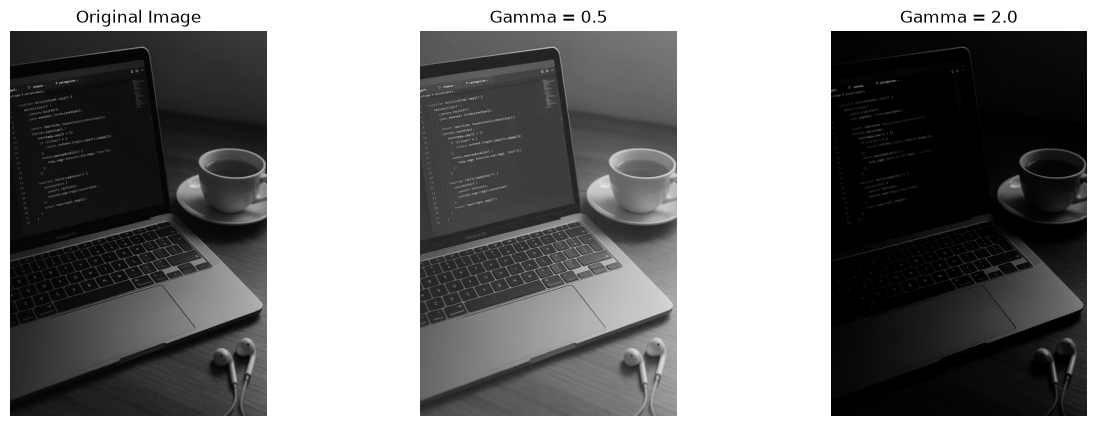

In [21]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_img_05, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_img_2, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 2.0")
plt.axis("off")

plt.show()

In [22]:
# Task 6: Histogram
A = np.array([
    [0, 50, 50, 100],
    [100, 150, 200, 255]
])

print("Array:")
print(A)

Array:
[[  0  50  50 100]
 [100 150 200 255]]


In [23]:
import numpy as np
import cv2

A = np.array([
    [0, 50, 50, 100],
    [100, 150, 200, 255]
], dtype=np.uint8)

hist = cv2.calcHist([A], [0], None, [256], [0, 256])

print("Histogram Shape:", hist.shape)

print("Intensity 0:", int(hist[0]))
print("Intensity 50:", int(hist[50]))
print("Intensity 100:", int(hist[100]))
print("Intensity 150:", int(hist[150]))
print("Intensity 200:", int(hist[200]))
print("Intensity 255:", int(hist[255]))

Histogram Shape: (256,)
Intensity 0: 1
Intensity 50: 2
Intensity 100: 2
Intensity 150: 1
Intensity 200: 1
Intensity 255: 1


In [24]:
total_pixels = A.size

probability = hist / total_pixels

print("Total Pixels:", total_pixels)

print("Probability of 0:", probability[0])
print("Probability of 50:", probability[50])
print("Probability of 100:", probability[100])
print("Probability of 150:", probability[150])
print("Probability of 200:", probability[200])
print("Probability of 255:", probability[255])

Total Pixels: 8
Probability of 0: 0.125
Probability of 50: 0.25
Probability of 100: 0.25
Probability of 150: 0.125
Probability of 200: 0.125
Probability of 255: 0.125


In [25]:
print("Sum of Probabilities:", probability.sum())

Sum of Probabilities: 1.0


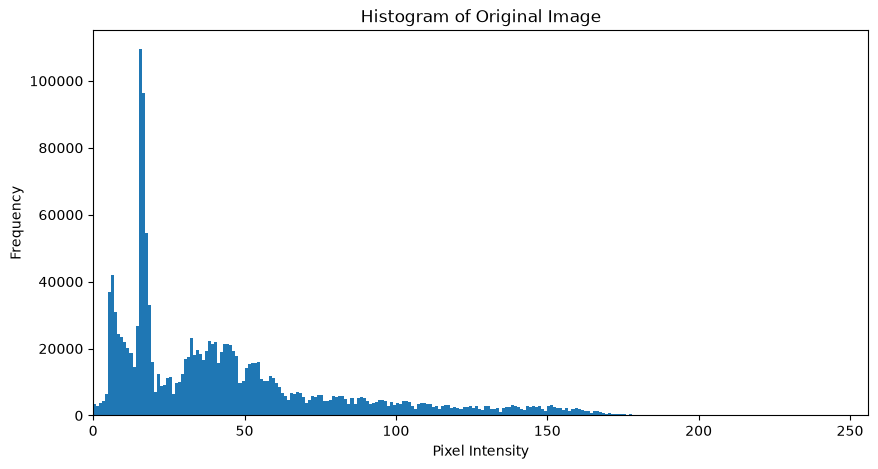

In [26]:
plt.figure(figsize=(10, 5))

plt.hist(img.ravel(), bins=256, range=[0, 256])

plt.title("Histogram of Original Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.xlim([0, 256])
plt.show()

In [27]:
# Task 7: Global Histogram Equalization
pixels = np.array([50, 50, 100, 150], dtype=np.uint8)

# Calculate histogram
hist = np.bincount(pixels, minlength=256)

# Calculate cumulative frequency
cdf = np.cumsum(hist)

# Calculate CDF minimum (first non-zero value)
cdf_min = cdf[np.nonzero(cdf)][0] / len(pixels)

# Normalize CDF
cdf_normalized = cdf / len(pixels)

# Apply equalization formula
equalized = 255 * (cdf_normalized - cdf_min) / (1 - cdf_min)

# Round to nearest integer (.5 goes upward)
equalized = np.floor(equalized + 0.5)
equalized = np.clip(equalized, 0, 255).astype(np.uint8)

# Apply mapping to original pixels
result = equalized[pixels]

print("Original Pixels:", pixels)
print("CDF Minimum:", cdf_min)
print("Equalized Pixels:", result)

Original Pixels: [ 50  50 100 150]
CDF Minimum: 0.5
Equalized Pixels: [  0   0 128 255]


In [28]:
opencv_result = cv2.equalizeHist(pixels.reshape(-1, 1))

opencv_result = opencv_result.flatten()

print("Manual Result:", result)
print("OpenCV Result:", opencv_result)

print("Both Results Same:", np.array_equal(result, opencv_result))

Manual Result: [  0   0 128 255]
OpenCV Result: [  0   0 128 255]
Both Results Same: True


In [29]:
equalized_img = cv2.equalizeHist(img)

print("Histogram Equalization Completed!")
print("Original Shape:", img.shape)
print("Equalized Shape:", equalized_img.shape)

Histogram Equalization Completed!
Original Shape: (1536, 1024)
Equalized Shape: (1536, 1024)


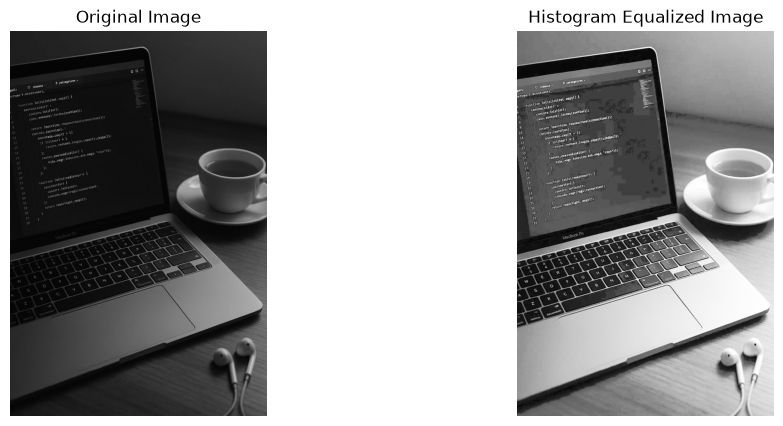

In [30]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.show()

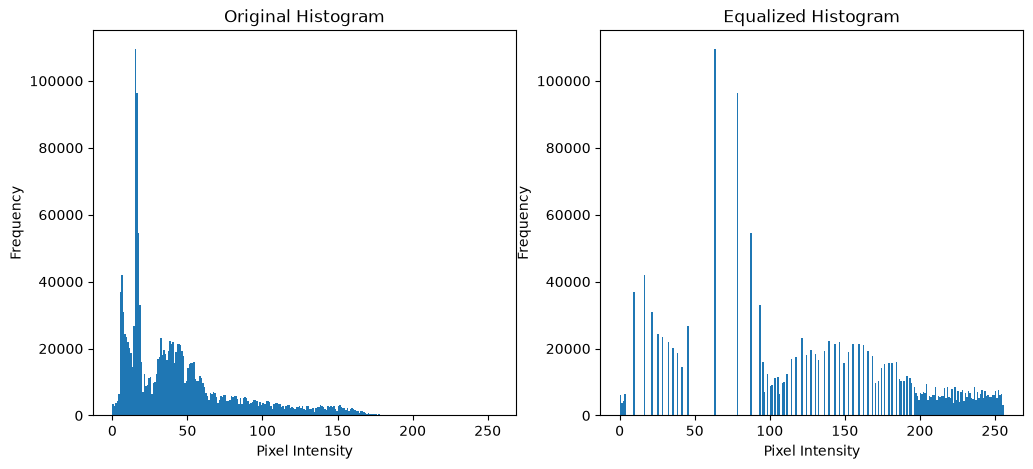

In [31]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(img.ravel(), bins=256, range=[0, 256])
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(equalized_img.ravel(), bins=256, range=[0, 256])
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

In [32]:
# Task 8: CLAHE
import numpy as np

hist = np.array([6, 2, 0, 0], dtype=float)

clip_cap = 4

# Clip histogram
clipped_hist = np.minimum(hist, clip_cap)

# Calculate excess
excess = np.sum(hist - clipped_hist)

# Redistribute excess equally
redistributed = clipped_hist + (excess / len(hist))

# Calculate CDF
cdf = np.cumsum(redistributed)

# Normalize CDF
normalized_cdf = cdf / np.sum(redistributed)

print("Original Histogram:", hist)
print("Clipped Histogram:", clipped_hist)
print("Excess:", excess)
print("Redistributed Histogram:", redistributed)
print("CDF:", cdf)
print("Normalized CDF:", normalized_cdf)

Original Histogram: [6. 2. 0. 0.]
Clipped Histogram: [4. 2. 0. 0.]
Excess: 2.0
Redistributed Histogram: [4.5 2.5 0.5 0.5]
CDF: [4.5 7.  7.5 8. ]
Normalized CDF: [0.5625 0.875  0.9375 1.    ]


In [33]:
# Create CLAHE object
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Apply CLAHE
clahe_img = clahe.apply(img)

print("CLAHE Applied Successfully!")
print("Original Shape:", img.shape)
print("CLAHE Image Shape:", clahe_img.shape)

CLAHE Applied Successfully!
Original Shape: (1536, 1024)
CLAHE Image Shape: (1536, 1024)


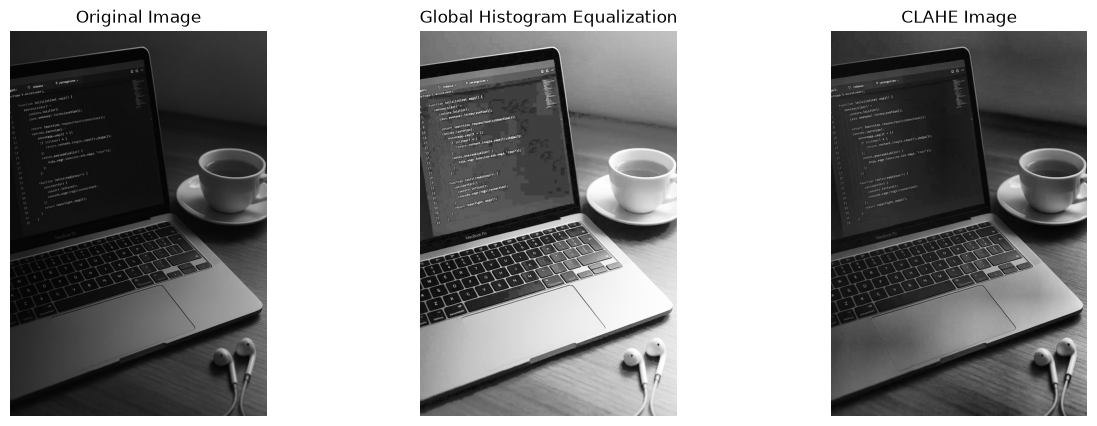

In [34]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Global Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_img, cmap="gray", vmin=0, vmax=255)
plt.title("CLAHE Image")
plt.axis("off")

plt.show()

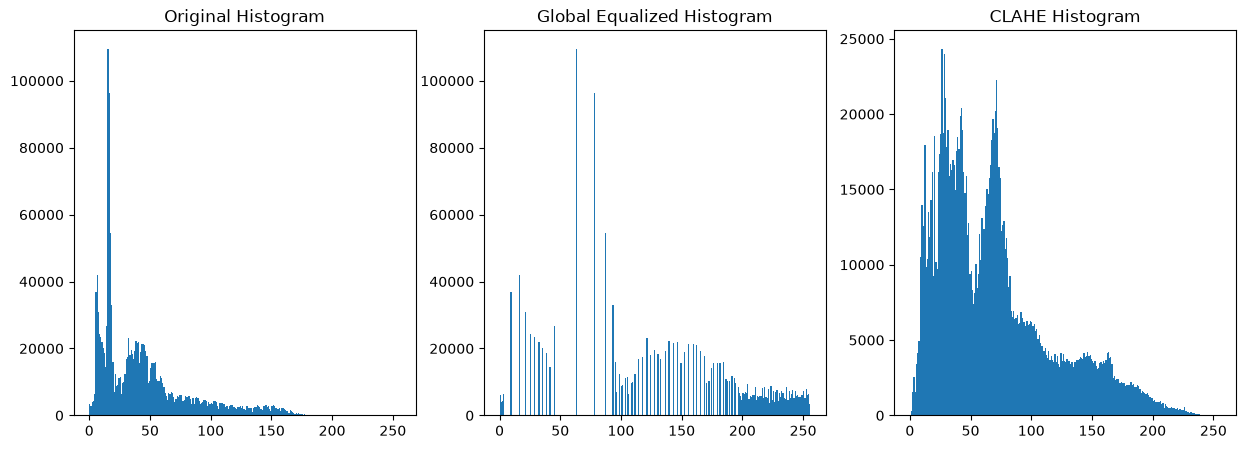

In [35]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(img.ravel(), bins=256, range=[0, 256])
plt.title("Original Histogram")

plt.subplot(1, 3, 2)
plt.hist(equalized_img.ravel(), bins=256, range=[0, 256])
plt.title("Global Equalized Histogram")

plt.subplot(1, 3, 3)
plt.hist(clahe_img.ravel(), bins=256, range=[0, 256])
plt.title("CLAHE Histogram")

plt.show()

In [36]:
# Task 9: Fixed Binary Thresholding
pixels = np.array([0, 80, 127, 128, 180, 255])

T = 127

binary = np.where(pixels > T, 255, 0).astype(np.uint8)

print("Original Pixels:", pixels)
print("Threshold:", T)
print("Binary Output:", binary)

Original Pixels: [  0  80 127 128 180 255]
Threshold: 127
Binary Output: [  0   0   0 255 255 255]


In [37]:
T = 180

binary_180 = np.where(pixels > T, 255, 0).astype(np.uint8)

print("Original Pixels:", pixels)
print("Threshold 180 Output:", binary_180)

print("White Pixels:", np.count_nonzero(binary_180 == 255))

Original Pixels: [  0  80 127 128 180 255]
Threshold 180 Output: [  0   0   0   0   0 255]
White Pixels: 1


In [38]:
T = 127

ret, binary_img = cv2.threshold(
    img,
    T,
    255,
    cv2.THRESH_BINARY
)

print("Threshold Value:", ret)
print("Unique Pixel Values:", np.unique(binary_img))

Threshold Value: 127.0
Unique Pixel Values: [  0 255]


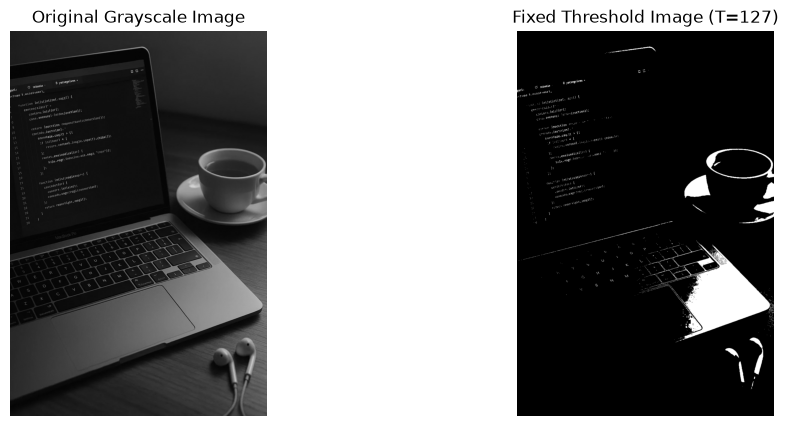

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold Image (T=127)")
plt.axis("off")

plt.show()

In [40]:
# Task 10: Otsu's Thresholding
pixels = np.array([0, 1, 4, 5], dtype=np.uint8)

thresholds = [0, 1, 2, 3, 4]

best_score = -1
best_threshold = None

for T in thresholds:

    group0 = pixels[pixels <= T]
    group1 = pixels[pixels > T]

    if len(group0) == 0 or len(group1) == 0:
        continue

    w0 = len(group0) / len(pixels)
    w1 = len(group1) / len(pixels)

    mean0 = np.mean(group0)
    mean1 = np.mean(group1)

    variance = w0 * w1 * (mean0 - mean1) ** 2

    print("Threshold:", T)
    print("Group 0:", group0)
    print("Group 1:", group1)
    print("Weight 0:", w0)
    print("Weight 1:", w1)
    print("Mean 0:", mean0)
    print("Mean 1:", mean1)
    print("Variance:", variance)
    print("----------------------")

    if variance > best_score:
        best_score = variance
        best_threshold = T

print("Best Threshold:", best_threshold)
print("Maximum Variance:", best_score)

Threshold: 0
Group 0: [0]
Group 1: [1 4 5]
Weight 0: 0.25
Weight 1: 0.75
Mean 0: 0.0
Mean 1: 3.3333333333333335
Variance: 2.0833333333333335
----------------------
Threshold: 1
Group 0: [0 1]
Group 1: [4 5]
Weight 0: 0.5
Weight 1: 0.5
Mean 0: 0.5
Mean 1: 4.5
Variance: 4.0
----------------------
Threshold: 2
Group 0: [0 1]
Group 1: [4 5]
Weight 0: 0.5
Weight 1: 0.5
Mean 0: 0.5
Mean 1: 4.5
Variance: 4.0
----------------------
Threshold: 3
Group 0: [0 1]
Group 1: [4 5]
Weight 0: 0.5
Weight 1: 0.5
Mean 0: 0.5
Mean 1: 4.5
Variance: 4.0
----------------------
Threshold: 4
Group 0: [0 1 4]
Group 1: [5]
Weight 0: 0.75
Weight 1: 0.25
Mean 0: 1.6666666666666667
Mean 1: 5.0
Variance: 2.083333333333333
----------------------
Best Threshold: 1
Maximum Variance: 4.0


In [41]:
ret, otsu_dry = cv2.threshold(
    pixels.reshape(-1, 1),
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold:", ret)
print("Predicted Binary Mask:", np.where(pixels > best_threshold, 255, 0))
print("OpenCV Binary Mask:", otsu_dry.flatten())

Otsu Threshold: 1.0
Predicted Binary Mask: [  0   0 255 255]
OpenCV Binary Mask: [  0   0 255 255]


In [42]:
otsu_threshold, otsu_img = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", otsu_threshold)
print("Unique Pixel Values:", np.unique(otsu_img))

Otsu Threshold Value: 69.0
Unique Pixel Values: [  0 255]


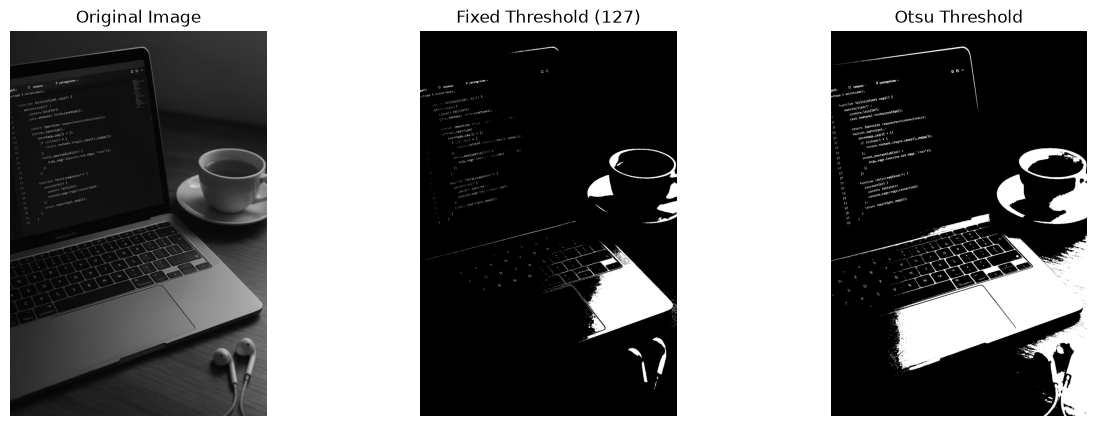

In [43]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray")
plt.title("Fixed Threshold (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_img, cmap="gray")
plt.title("Otsu Threshold")
plt.axis("off")

plt.show()

In [44]:
# Task 11: Adaptive Gaussian Thresholding
neighborhood = np.array([
    [100, 100, 100],
    [100, 120, 140],
    [140, 140, 140]
])

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]) / 16

# Calculate weighted mean
weighted_mean = np.sum(neighborhood * weights)

# Calculate threshold
C = 2
T = weighted_mean - C

# Center pixel
center_pixel = neighborhood[1, 1]

# Classify center pixel
if center_pixel > T:
    result = 255
else:
    result = 0

print("Weighted Mean:", weighted_mean)
print("C Value:", C)
print("Threshold:", T)
print("Center Pixel:", center_pixel)
print("Final Output:", result)

Weighted Mean: 120.0
C Value: 2
Threshold: 118.0
Center Pixel: 120
Final Output: 255


In [45]:
T = 118
pixel = 118

if pixel > T:
    result = 255
else:
    result = 0

print("Output:", result)

Output: 0


In [46]:
adaptive_img = cv2.adaptiveThreshold(
    img,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

print("Adaptive Thresholding Completed!")
print("Original Shape:", img.shape)
print("Adaptive Image Shape:", adaptive_img.shape)
print("Unique Pixel Values:", np.unique(adaptive_img))

Adaptive Thresholding Completed!
Original Shape: (1536, 1024)
Adaptive Image Shape: (1536, 1024)
Unique Pixel Values: [  0 255]


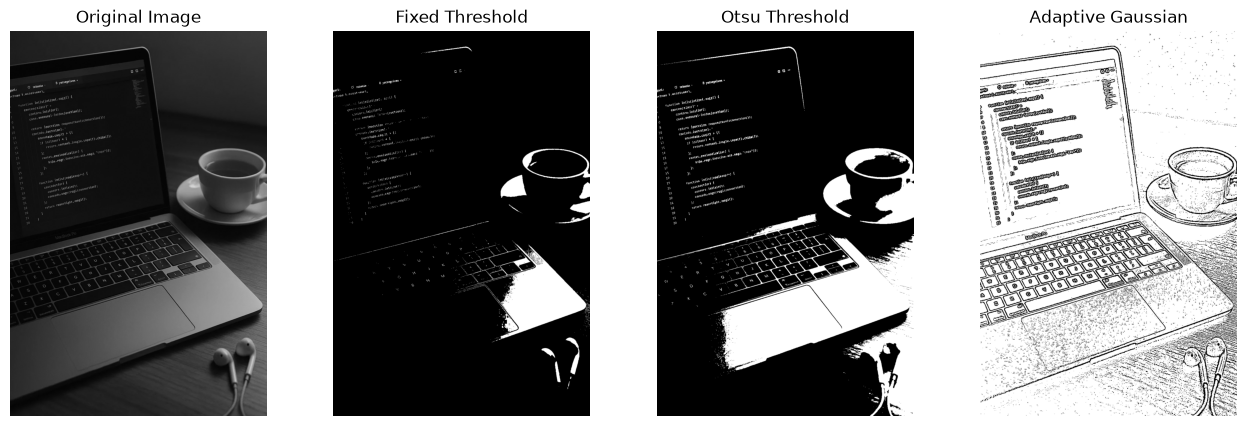

In [47]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(binary_img, cmap="gray")
plt.title("Fixed Threshold")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(otsu_img, cmap="gray")
plt.title("Otsu Threshold")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(adaptive_img, cmap="gray")
plt.title("Adaptive Gaussian")
plt.axis("off")

plt.show()